In [1]:
'''Analyze feature importance scores generated from tree-based models like Random Forest and XGBoost to understand the key factors influencing university admission decisions.'''

'Analyze feature importance scores generated from tree-based models like Random Forest and XGBoost to understand the key factors influencing university admission decisions.'

In [2]:
# import libraries and load dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv('Adm.csv')
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.96,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.80,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.67,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.78,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.63,2022-01-08 09:00:00,Jamia Millia Islamia,North


In [3]:
# prepare features and train test split
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
target = 'Chance of Admit'

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Training set size:', X_train.shape, 'Test set size:', X_test.shape)

Training set size: (800, 7) Test set size: (200, 7)


In [4]:
# train random forest and xgboost models
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

xgb_model = XGBRegressor(n_estimators=100, random_state=42)
xgb_model.fit(X_train, y_train)

print('Random Forest R2:', round(rf_model.score(X_test, y_test), 3))
print('XGBoost R2:', round(xgb_model.score(X_test, y_test), 3))

Random Forest R2: 0.908
XGBoost R2: 0.92


In [5]:
# extract and compare feature importance scores
importance_df = pd.DataFrame({
    'Criteria': features,
    'Random Forest Score': rf_model.feature_importances_,
    'XGBoost Score': xgb_model.feature_importances_
}).sort_values(by='Random Forest Score', ascending=False)

importance_df['RF Percentage'] = (importance_df['Random Forest Score'] * 100).round(2)
importance_df['XGB Percentage'] = (importance_df['XGBoost Score'] * 100).round(2)
importance_df

,Criteria,Random Forest Score,XGBoost Score,RF Percentage,XGB Percentage
5,CGPA,0.782794,0.626655,78.28,62.669998
0,GRE Score,0.080623,0.060681,8.06,6.070000
1,TOEFL Score,0.063816,0.067127,6.38,6.710000
4,LOR,0.035542,0.050788,3.55,5.080000
6,Research,0.016311,0.157228,1.63,15.720000
2,University Rating,0.010542,0.026476,1.05,2.650000
3,SOP,0.010372,0.011045,1.04,1.100000


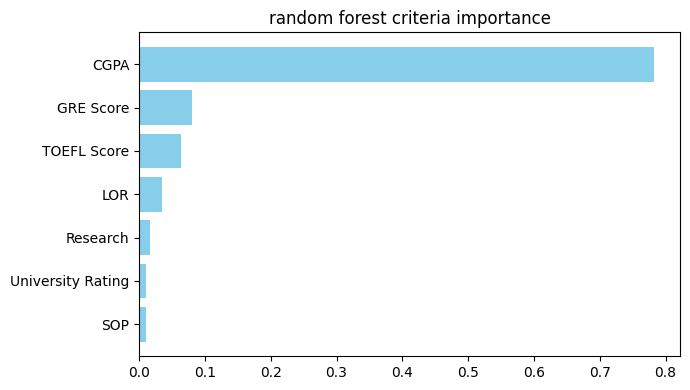

In [6]:
# plot random forest feature importance
plt.figure(figsize=(7, 4))
plt.barh(importance_df['Criteria'], importance_df['Random Forest Score'], color='skyblue')
plt.title('random forest criteria importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

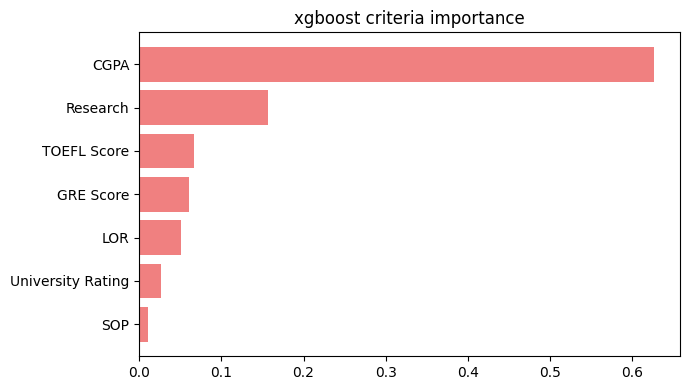

In [7]:
# plot xgboost feature importance
xgb_sorted = importance_df.sort_values(by='XGBoost Score', ascending=False)
plt.figure(figsize=(7, 4))
plt.barh(xgb_sorted['Criteria'], xgb_sorted['XGBoost Score'], color='lightcoral')
plt.title('xgboost criteria importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

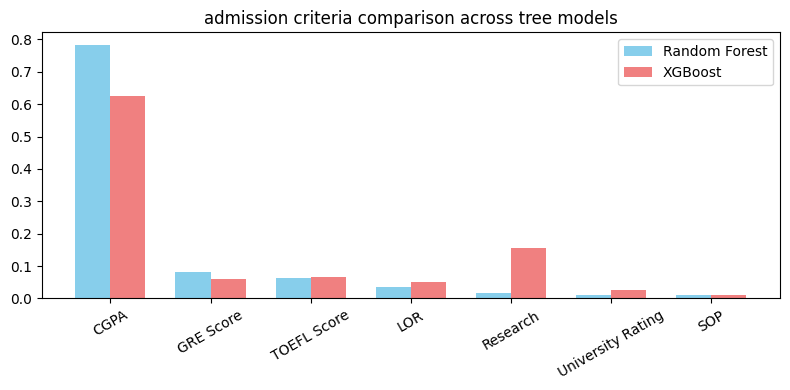

In [8]:
# plot side by side feature importance comparison
plt.figure(figsize=(8, 4))
x = np.arange(len(features))
width = 0.35

plt.bar(x - width/2, importance_df['Random Forest Score'], width, label='Random Forest', color='skyblue')
plt.bar(x + width/2, importance_df['XGBoost Score'], width, label='XGBoost', color='lightcoral')
plt.xticks(x, importance_df['Criteria'], rotation=30)
plt.title('admission criteria comparison across tree models')
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
# rank key factors influencing university admission
importance_df['Average Score'] = (importance_df['Random Forest Score'] + importance_df['XGBoost Score']) / 2
ranked_df = importance_df[['Criteria', 'Average Score']].sort_values(by='Average Score', ascending=False)

print('Primary Criteria for Admission Decision:')
for rank, (_, row) in enumerate(ranked_df.iterrows(), 1):
    print(f"{rank}. {row['Criteria']}: {round(row['Average Score'], 4)}")

Primary Criteria for Admission Decision:
1. CGPA: 0.7047
2. Research: 0.0868
3. GRE Score: 0.0707
4. TOEFL Score: 0.0655
5. LOR: 0.0432
6. University Rating: 0.0185
7. SOP: 0.0107


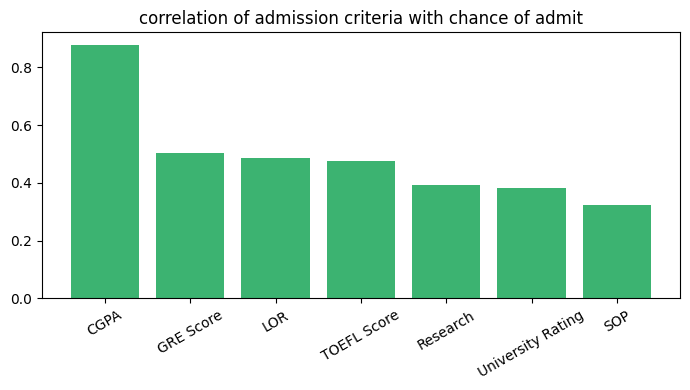

In [10]:
# analyze correlation between admission criteria and admission chance
corr_scores = df[features].apply(lambda col: df['Chance of Admit'].corr(col)).sort_values(ascending=False)

plt.figure(figsize=(7, 4))
plt.bar(corr_scores.index, corr_scores.values, color='mediumseagreen')
plt.xticks(rotation=30)
plt.title('correlation of admission criteria with chance of admit')
plt.tight_layout()
plt.show()